# Market Making with Inventory Risk (Avellaneda-Stoikov)

A market maker shows a bid and an ask all day. Each time a client trades, it earns half the
spread, but it also ends up holding the client's position. After a run of sellers, it is long
and exposed to the price falling. The question every flow trader faces: **how wide should I
quote, and how should I move my prices when my inventory builds up?**

Avellaneda and Stoikov (2008) give a closed-form answer for a dealer with risk aversion $\gamma$,
a mid price with volatility $\sigma$, and clients who arrive less often the further the quote is
from the mid, $\lambda(\delta) = A e^{-k\delta}$:

$$r = s - q\,\gamma\sigma^2(T-t) \qquad\qquad \delta^a + \delta^b = \gamma\sigma^2(T-t) + \tfrac{2}{\gamma}\ln\!\left(1 + \tfrac{\gamma}{k}\right)$$

The dealer quotes around a **reservation price** $r$ shifted against its inventory $q$: when
long, both quotes move down, so the dealer buys less and sells more. The benchmark is a
dealer quoting the same spread symmetrically around the mid.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("mm.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/26-market-making")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mm import Params, simulate, summary, optimal_spread, reservation_price

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
p = Params()
p

Params(s0=100.0, T=1.0, sigma=2.0, dt=0.005, A=140.0, k=1.5, gamma=0.1, max_inventory=None)

## 1. One trading day, two dealers

Same market, same clients (same random numbers). The inventory-aware dealer leans its quotes
against its position; the symmetric dealer does not.

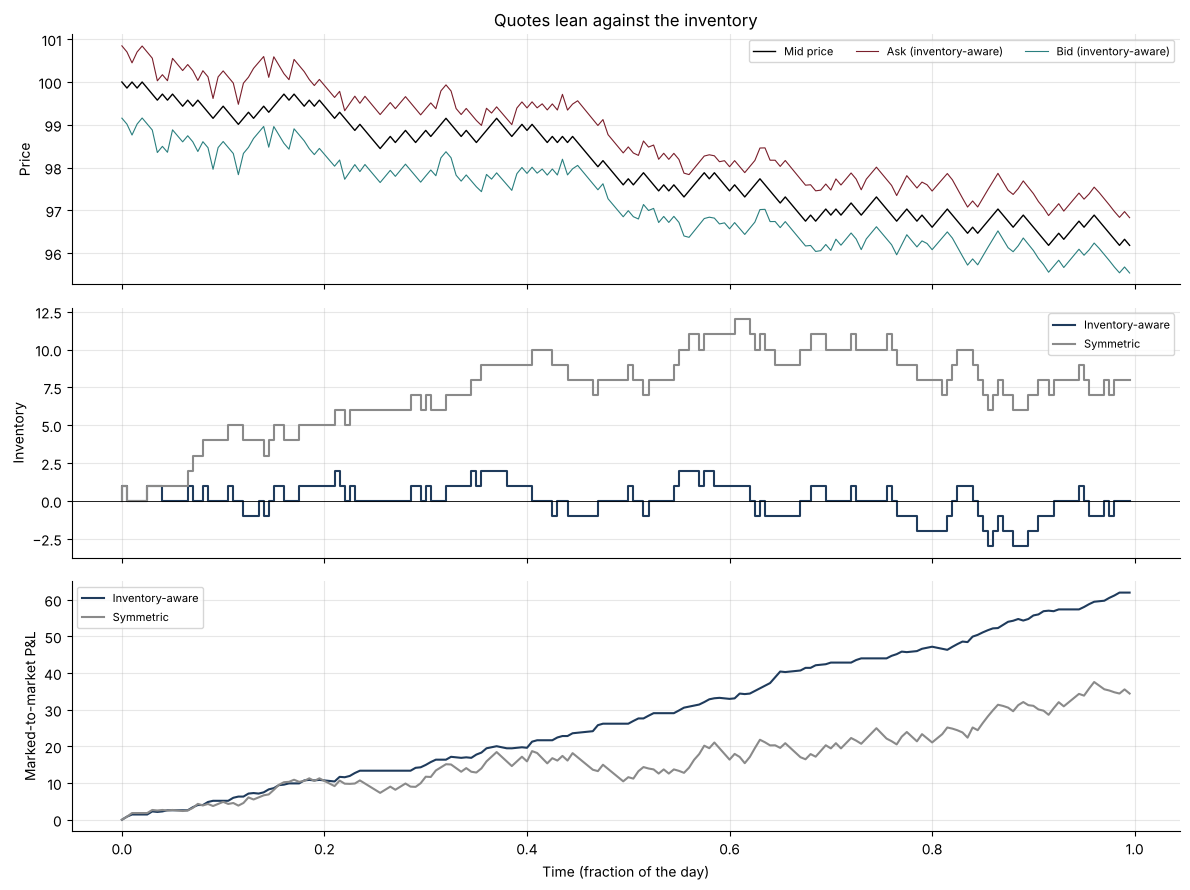

In [2]:
inv1 = simulate(p, "inventory", n_paths=1, seed=4, record=True)["path"]
sym1 = simulate(p, "symmetric", n_paths=1, seed=4, record=True)["path"]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(inv1["t"], inv1["mid"], color="black", lw=1, label="Mid price")
axes[0].plot(inv1["t"], inv1["ask"], color=BORDEAUX, lw=0.8, label="Ask (inventory-aware)")
axes[0].plot(inv1["t"], inv1["bid"], color=TEAL, lw=0.8, label="Bid (inventory-aware)")
axes[0].set(ylabel="Price", title="Quotes lean against the inventory"); axes[0].legend(fontsize=8, ncol=3)
axes[1].step(inv1["t"], inv1["inventory"], color=NAVY, label="Inventory-aware")
axes[1].step(sym1["t"], sym1["inventory"], color=GREY, label="Symmetric")
axes[1].axhline(0, color="black", lw=0.6); axes[1].set(ylabel="Inventory"); axes[1].legend(fontsize=8)
axes[2].plot(inv1["t"], inv1["pnl"], color=NAVY, label="Inventory-aware")
axes[2].plot(sym1["t"], sym1["pnl"], color=GREY, label="Symmetric")
axes[2].set(xlabel="Time (fraction of the day)", ylabel="Marked-to-market P&L"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/one_day.png", dpi=150); plt.show()

## 2. A thousand days: earning the spread vs carrying risk

The same experiment repeated over 2,000 independent days, as in the paper.

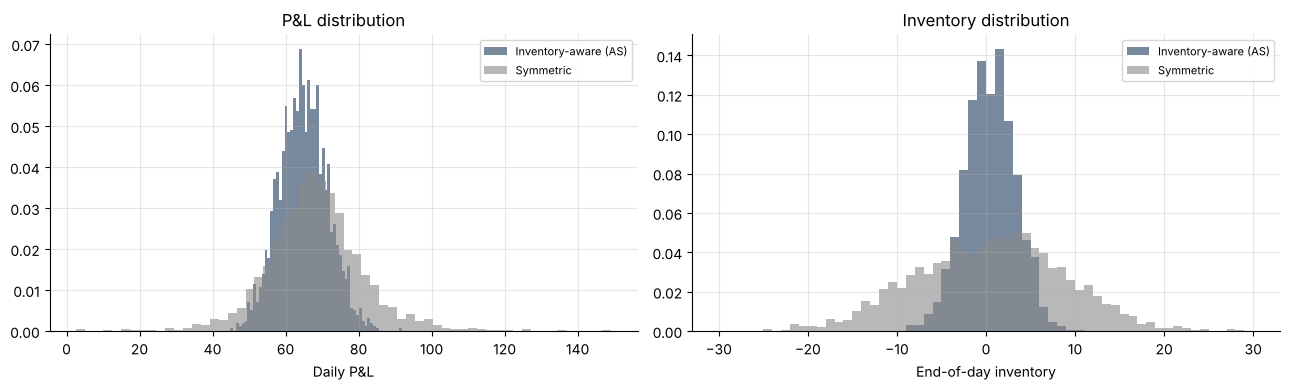

,Mean P&L,Std P&L,Sharpe (per day),Mean |final inventory|,Std final inventory,Trades per day
Inventory-aware (AS),64.88,6.62,9.80,2.27,2.86,96.86
Symmetric,68.14,13.33,5.11,6.70,8.35,91.58


In [3]:
res = {"Inventory-aware (AS)": simulate(p, "inventory", 2000, seed=1), "Symmetric": simulate(p, "symmetric", 2000, seed=1)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, r), c in zip(res.items(), [NAVY, GREY]):
    axes[0].hist(r["pnl"], bins=60, alpha=0.6, color=c, label=name, density=True)
    axes[1].hist(r["inventory"], bins=np.arange(-30, 31), alpha=0.6, color=c, label=name, density=True)
axes[0].set(xlabel="Daily P&L", title="P&L distribution"); axes[1].set(xlabel="End-of-day inventory", title="Inventory distribution")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/distributions.png", dpi=150); plt.show()
pd.DataFrame({k: summary(v) for k, v in res.items()}).T.round(2)

**Reading the result.** The symmetric dealer earns slightly more on average, but with twice
the P&L volatility: it is running a directional position it never chose. Skewing the quotes
gives up a little spread to halve the risk, and doubles the risk-adjusted return.

## 3. Risk aversion: choosing a point on the frontier

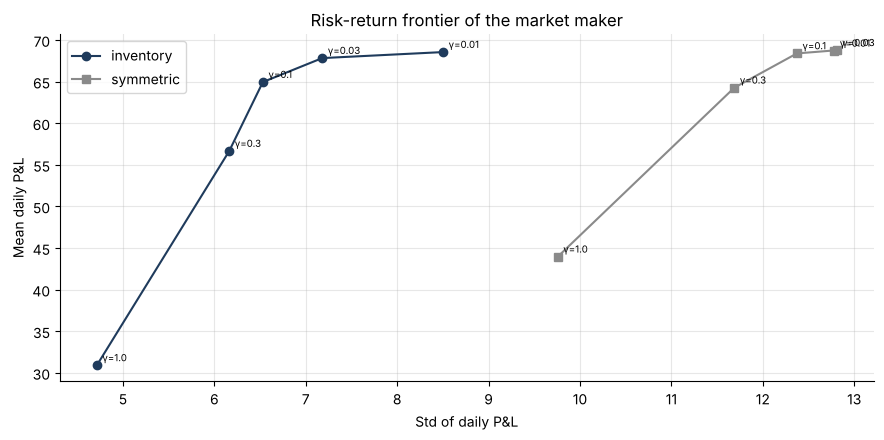

Mean P&L             Std P&L          
strategy inventory symmetric inventory symmetric
gamma                                           
0.01         68.55     68.70      8.50     12.78
0.03         67.83     68.77      7.18     12.81
0.10         64.95     68.39      6.53     12.37
0.30         56.66     64.27      6.16     11.69
1.00         30.90     43.96      4.71      9.76

In [4]:
gammas = [0.01, 0.03, 0.1, 0.3, 1.0]
rows = []
for g in gammas:
    pg = replace(p, gamma=g)
    for strat in ["inventory", "symmetric"]:
        s = summary(simulate(pg, strat, 1500, seed=2))
        rows.append({"gamma": g, "strategy": strat, **s, "spread at t=0": optimal_spread(0, pg)})
front = pd.DataFrame(rows)
plt.figure(figsize=(9, 4.5))
for strat, c, m in [("inventory", NAVY, "o"), ("symmetric", GREY, "s")]:
    d = front[front["strategy"] == strat]
    plt.plot(d["Std P&L"], d["Mean P&L"], marker=m, color=c, label=strat)
    for _, r in d.iterrows():
        plt.annotate(f"γ={r['gamma']}", (r["Std P&L"], r["Mean P&L"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.xlabel("Std of daily P&L"); plt.ylabel("Mean daily P&L"); plt.legend()
plt.title("Risk-return frontier of the market maker")
plt.tight_layout(); plt.savefig("images/frontier.png", dpi=150); plt.show()
front.pivot(index="gamma", columns="strategy", values=["Mean P&L", "Std P&L"]).round(2)

A low risk aversion gives tight spreads and lots of trades, but large inventories; a high
one gives wide spreads, few trades and little risk. At every level of risk aversion, the
inventory-aware dealer cuts the P&L volatility by a third to a half for a modest loss of mean P&L,
so its risk-adjusted return is always higher.

## 4. When volatility spikes

In [5]:
vols = [1.0, 2.0, 3.0, 4.0]
vol_rows = []
for v in vols:
    pv = replace(p, sigma=v)
    s = summary(simulate(pv, "inventory", 1500, seed=3))
    vol_rows.append({"sigma": v, "spread at t=0": optimal_spread(0, pv), **s})
pd.DataFrame(vol_rows).set_index("sigma").round(2)

,spread at t=0,Mean P&L,Std P&L,Sharpe (per day),Mean |final inventory|,Std final inventory,Trades per day
sigma,,,,,,,
1.0,1.39,67.94,6.30,10.79,3.23,4.08,103.81
2.0,1.69,64.89,6.48,10.01,2.19,2.79,97.01
3.0,2.19,59.62,6.70,8.90,1.76,2.25,87.58
4.0,2.89,52.23,6.77,7.71,1.50,1.93,76.30


Higher volatility makes inventory more dangerous, so the optimal spread widens and the dealer
trades less. This is exactly what happens on real screens when markets get stressed.

## Conclusions
- The simulation reproduces the paper's results: inventory-aware quoting halves P&L risk
  for a small cost in mean P&L.
- The tests check the formulas, the fill intensity and the inventory control.
- **Next steps:** adverse selection (informed clients), a running inventory penalty, a
  multi-asset dealer hedging with a correlated instrument, and calibration of A and k to order-book data.